In [13]:
import numpy as np
import pandas as pd
from matplotlib import rc, rcParams
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
import textwrap
from scipy.stats import dunnett, levene, bartlett, tukey_hsd, kruskal
from sklearn.cluster import KMeans
from pathlib import Path

In [14]:
path2figs = Path("figs")
path2figs.mkdir(parents=True, exist_ok=True)
path2stats = "/mnt/cephfs/mir/jcaicedo/projects/de/movies/analysis/results/combined_dataframe.csv"

In [15]:
# Load dataframe, restrict to only green cells:
df = pd.read_csv(path2stats)
_drop_cols = ['color', 'red', 'green', 'entropy', 'parent', 'intensity']
df = df[df['color'] == 'g'].drop(columns=_drop_cols).reset_index(drop=True)

df = df[df['d_heart'] <= 2200]
df = df.reset_index(drop=True)

### The PDF/CDF of unique green cells in each video

In [16]:
df_n_frames = df.groupby(['vclass', 'vidx'])['frame'].nunique().reset_index(name='n_frames')
df_time_minutes = df.groupby(['vclass', 'vidx', 'frame'])['time_minutes'].mean().reset_index()

In [17]:
df_n_green_time = pd.DataFrame()
for idx, row in df_n_frames.iterrows():
    vclass, vidx, n_frames = row.vclass, row.vidx, row.n_frames

    row = []
    n_green_max = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame <= n_frames)]['label'].nunique()
    for frame in range(n_frames):
        n_green_in_frame = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame == frame)]['label'].nunique()
        n_green_cdf = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame <= frame)]['label'].nunique() / n_green_max
        time_minutes = df_time_minutes[(df_time_minutes.vclass == vclass) & (df_time_minutes.vidx == vidx) & (df_time_minutes.frame == frame)]['time_minutes'].item()

        row.append({
            'vclass': vclass, 
            'vidx': vidx, 
            'frame': frame, 
            'time_hours': time_minutes/60, 
            'n_green_in_frame': n_green_in_frame, 
            'n_green_cdf': n_green_cdf})
    # end for

    df_n_green_time = pd.concat([df_n_green_time, pd.DataFrame(row)])
# end for

df_n_green_time['n_green_pdf'] = df_n_green_time.groupby(['vclass', 'vidx'])['n_green_cdf'].transform(lambda x: x.diff()).fillna(0)
df_n_green_time['n_green_pdf'] = (
    df_n_green_time.groupby(['vclass', 'vidx'])['n_green_pdf']
    .transform(lambda x: x / x.sum())
)

df_n_green_time['delta_n_green_in_frame'] = df_n_green_time.groupby(['vclass', 'vidx'])['n_green_in_frame'].transform(lambda x: x - x.iloc[0]).fillna(0)

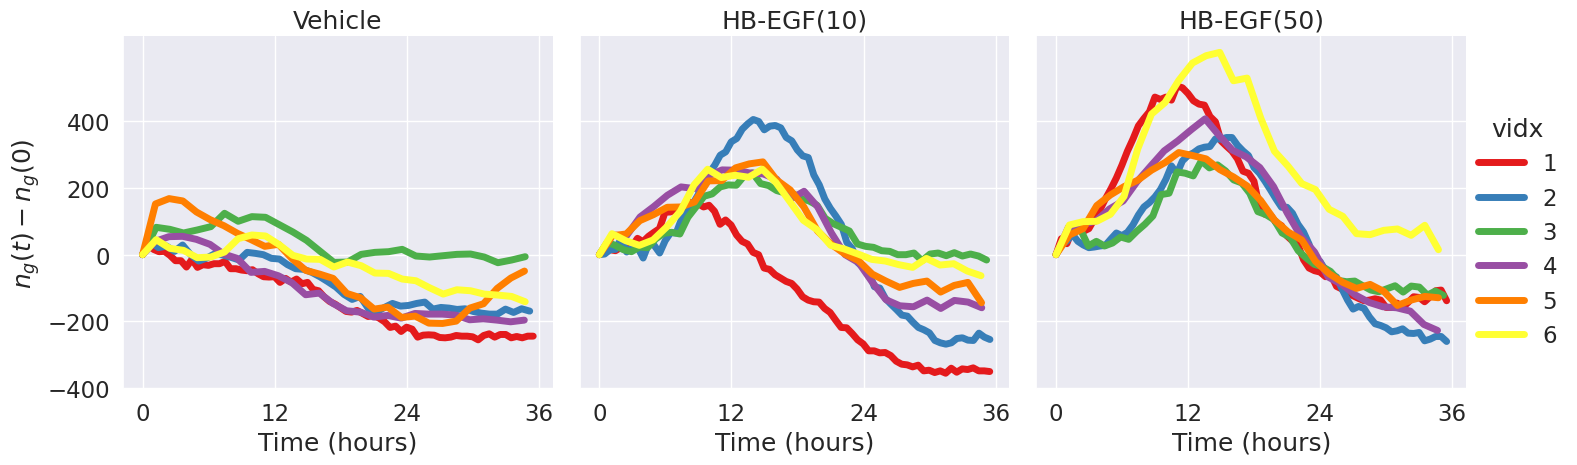

In [18]:
def _():
    sns.set_theme(font_scale=1.5)
    g = sns.relplot(data=df_n_green_time, kind='line', 
                x='time_hours', y='delta_n_green_in_frame', 
                col='vclass', col_order=['vehicle', 'hb_egf_10', 'hb_egf_50'],
                hue='vidx',
                lw=5,
                palette='Set1')

    # set custom col titles
    col_titles = [
        "Vehicle", 
        "HB-EGF(10)", 
        "HB-EGF(50)"
    ]
    for ax, title in zip(g.axes.flat, col_titles):
        ax.set_title(title)
    g.set(xlabel='Time (hours)', ylabel=r'$n_g(t) - n_g(0)$')
    plt.xticks([0, 12, 24, 36])
    plt.yticks([-400, -200, 0, 200, 400])

    plt.savefig(path2figs / 'n_alive.pdf')

    return g


_()

### Green cell density relative to heart CM

In [19]:
df['x_cm_rel_heart'] = df['d_heart'] * np.cos(df['angle_heart_rad'])
df['y_cm_rel_heart'] = df['d_heart'] * np.sin(df['angle_heart_rad'])

In [20]:
# find the time_minutes closest to the target times
target_times = [4, 8, 12, 16, 20, 24, 28, 32, 36]
df_hours = df.groupby(['vclass', 'vidx'])['time_minutes']\
    .apply(lambda s: s.loc[abs(s - target_times[0]*60).idxmin()])\
    .reset_index(name=f'{target_times[0]:02d} h')

for t in range(1, len(target_times)):
    tt = target_times[t]
    df_hours[f'{tt:02d} h'] = df.groupby(['vclass', 'vidx'])['time_minutes'].\
        apply(lambda s: s.loc[abs(s - tt*60).idxmin()]).values
# end for

In [21]:
for i in range(len(df_hours)):
    row = df_hours.iloc[i]
    time_mapping = {row[f'{tt:02d} h'] : f'{tt:02d}h' for tt in target_times}

    cond = (df.vclass == row.vclass) & (df.vidx == row.vidx)
    df.loc[cond, 'time'] = df.loc[cond, 'time_minutes'].map(time_mapping)
# end for

df_hours = df[~df.time.isna()].reset_index().copy()

In [22]:
def draw_avg_heart_circle(data, **kwargs):
    avg_radius = data['heart_radius'].mean()
    circle = plt.Circle((0, 0), avg_radius, color='pink', fill=False, linewidth=10, linestyle='-', alpha=0.5)

    ax = plt.gca()
    ax.add_patch(circle)

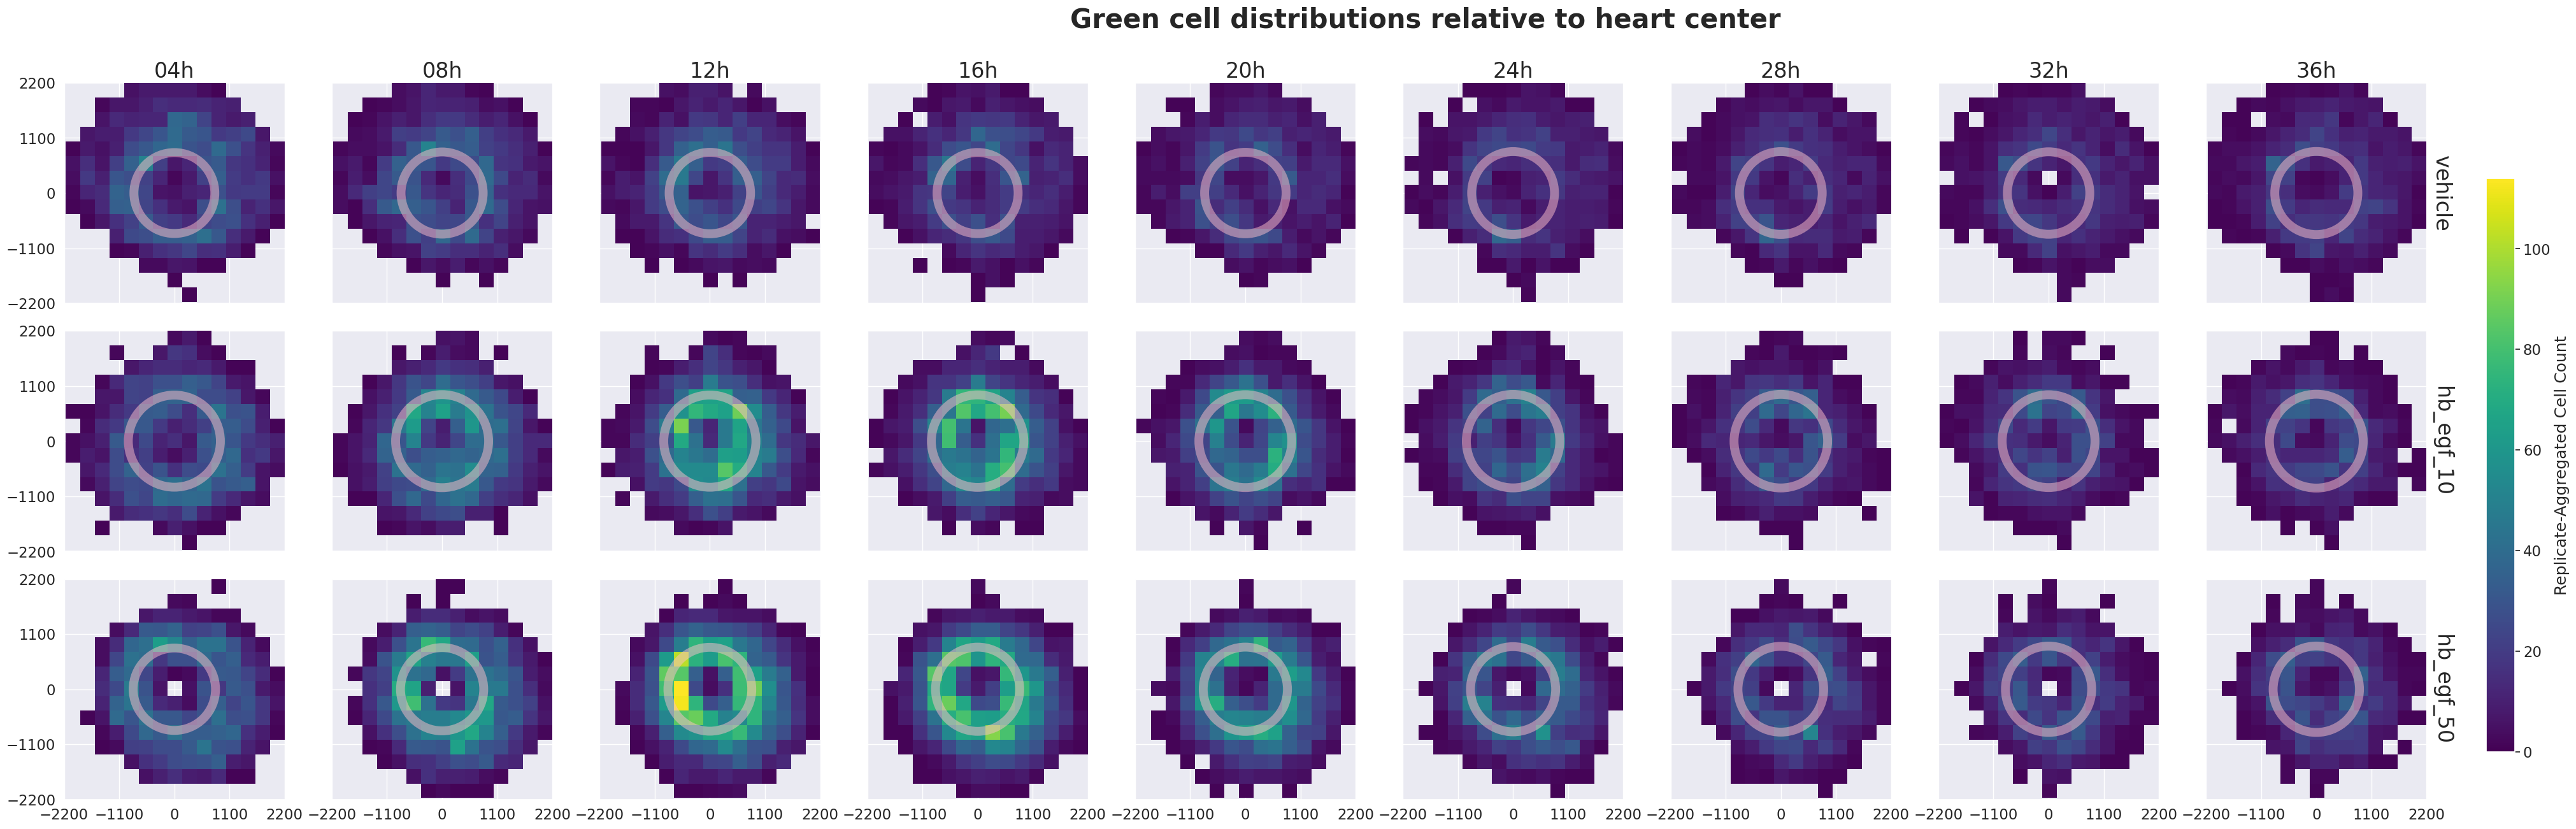

In [23]:
def _():
    col_order = [f'{tt:02d}h' for tt in target_times]
    g_kde_frame = sns.displot(kind='hist', data=df_hours,
                col='time',
                col_order=col_order,
                row='vclass',
                x='x_cm_rel_heart', y='y_cm_rel_heart',
                bins=15,
                cmap='viridis',
                facet_kws={'margin_titles': True},
                cbar=False,
                height=5,
                aspect=1
    )

    xticks = [-2200, -1100, 0, 1100, 2200]
    yticks = [-2200, -1100, 0, 1100, 2200]
    
    g_kde_frame.set(
        xticks=xticks, 
        xlim=(min(xticks), max(xticks)),
        yticks=yticks, 
        ylim=(min(xticks), max(xticks)),
        aspect='equal'
    )

    g_kde_frame.set_axis_labels("", "", fontsize=24)
    g_kde_frame.set_titles(col_template="{col_name}", row_template="{row_name}", size=24)

    g_kde_frame.figure.suptitle("Green cell distributions relative to heart center", fontsize=30, fontweight='bold')
    
    g_kde_frame.map_dataframe(draw_avg_heart_circle)

    g_kde_frame.figure.subplots_adjust(top=0.9, bottom=0.15, right=0.85)

    cax = g_kde_frame.figure.add_axes([0.87, 0.2, 0.01, 0.6])

    im = g_kde_frame.axes.flat[0].collections[0]

    cbar = g_kde_frame.figure.colorbar(im, cax=cax, label='Replicate-Aggregated Cell Count')
    
    cbar.ax.yaxis.set_ticks_position('right')
    cbar.ax.yaxis.set_label_position('right')

    plt.savefig(path2figs / 'density_class.pdf')

_()

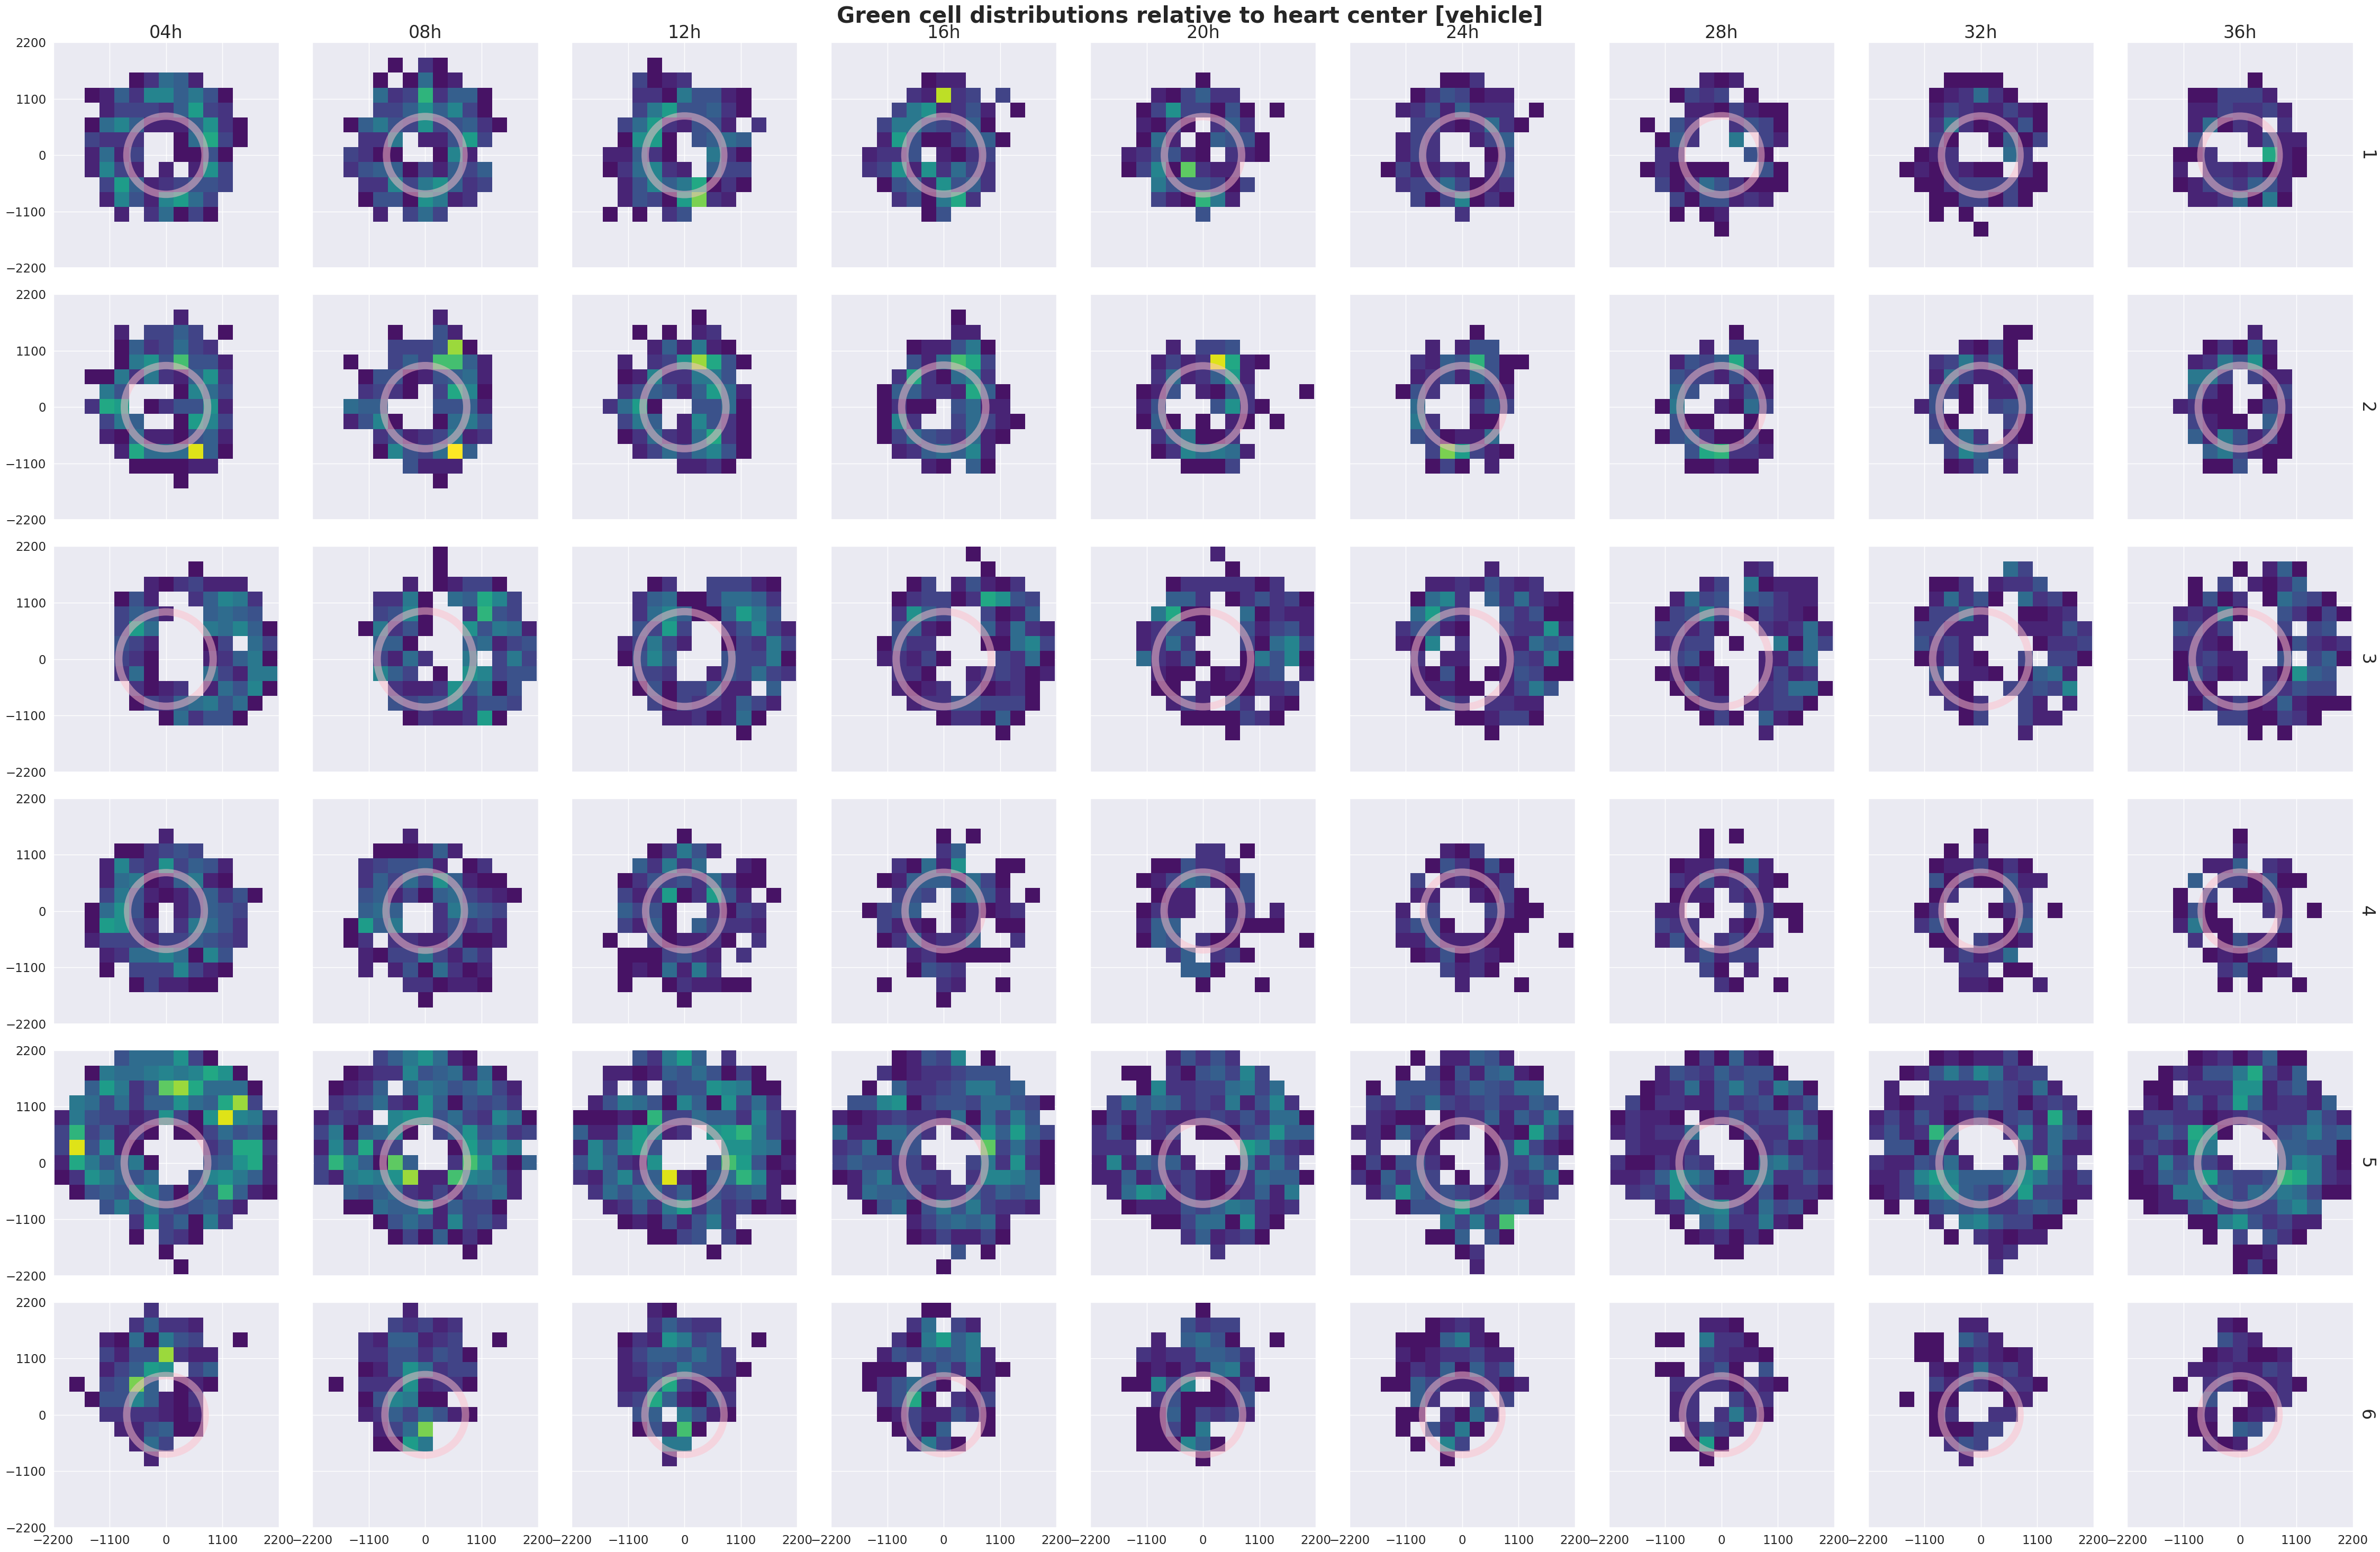

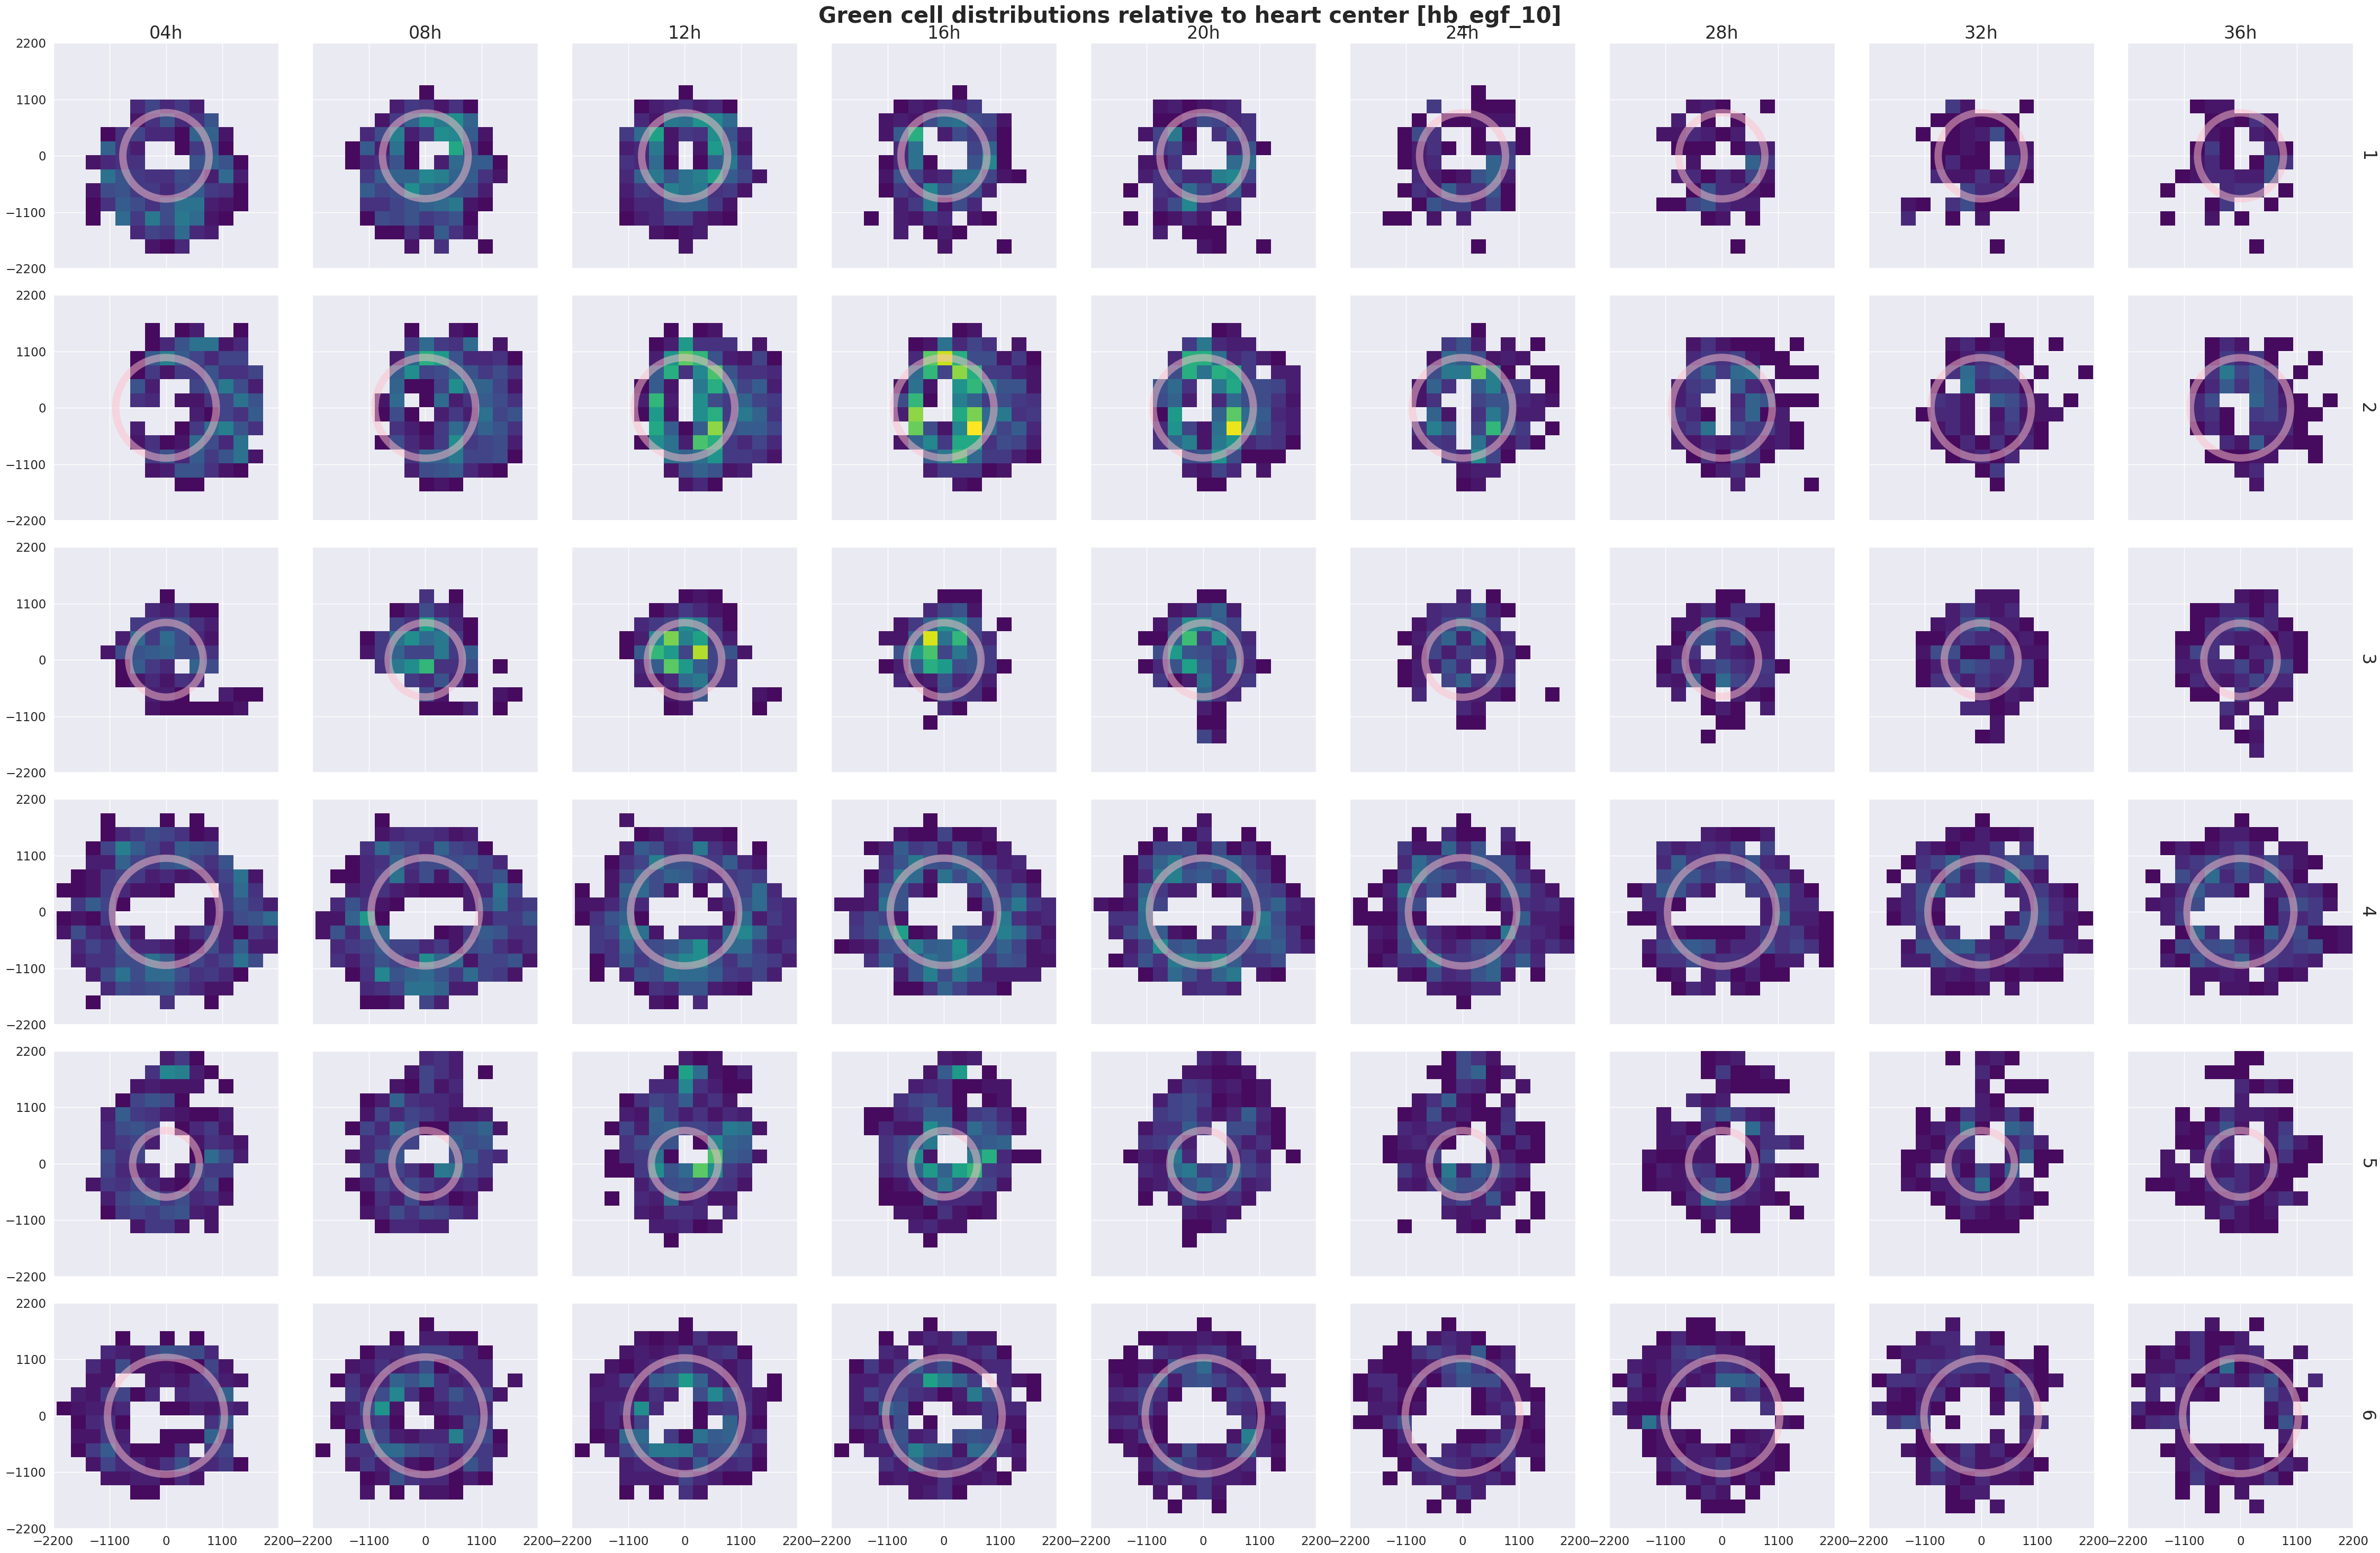

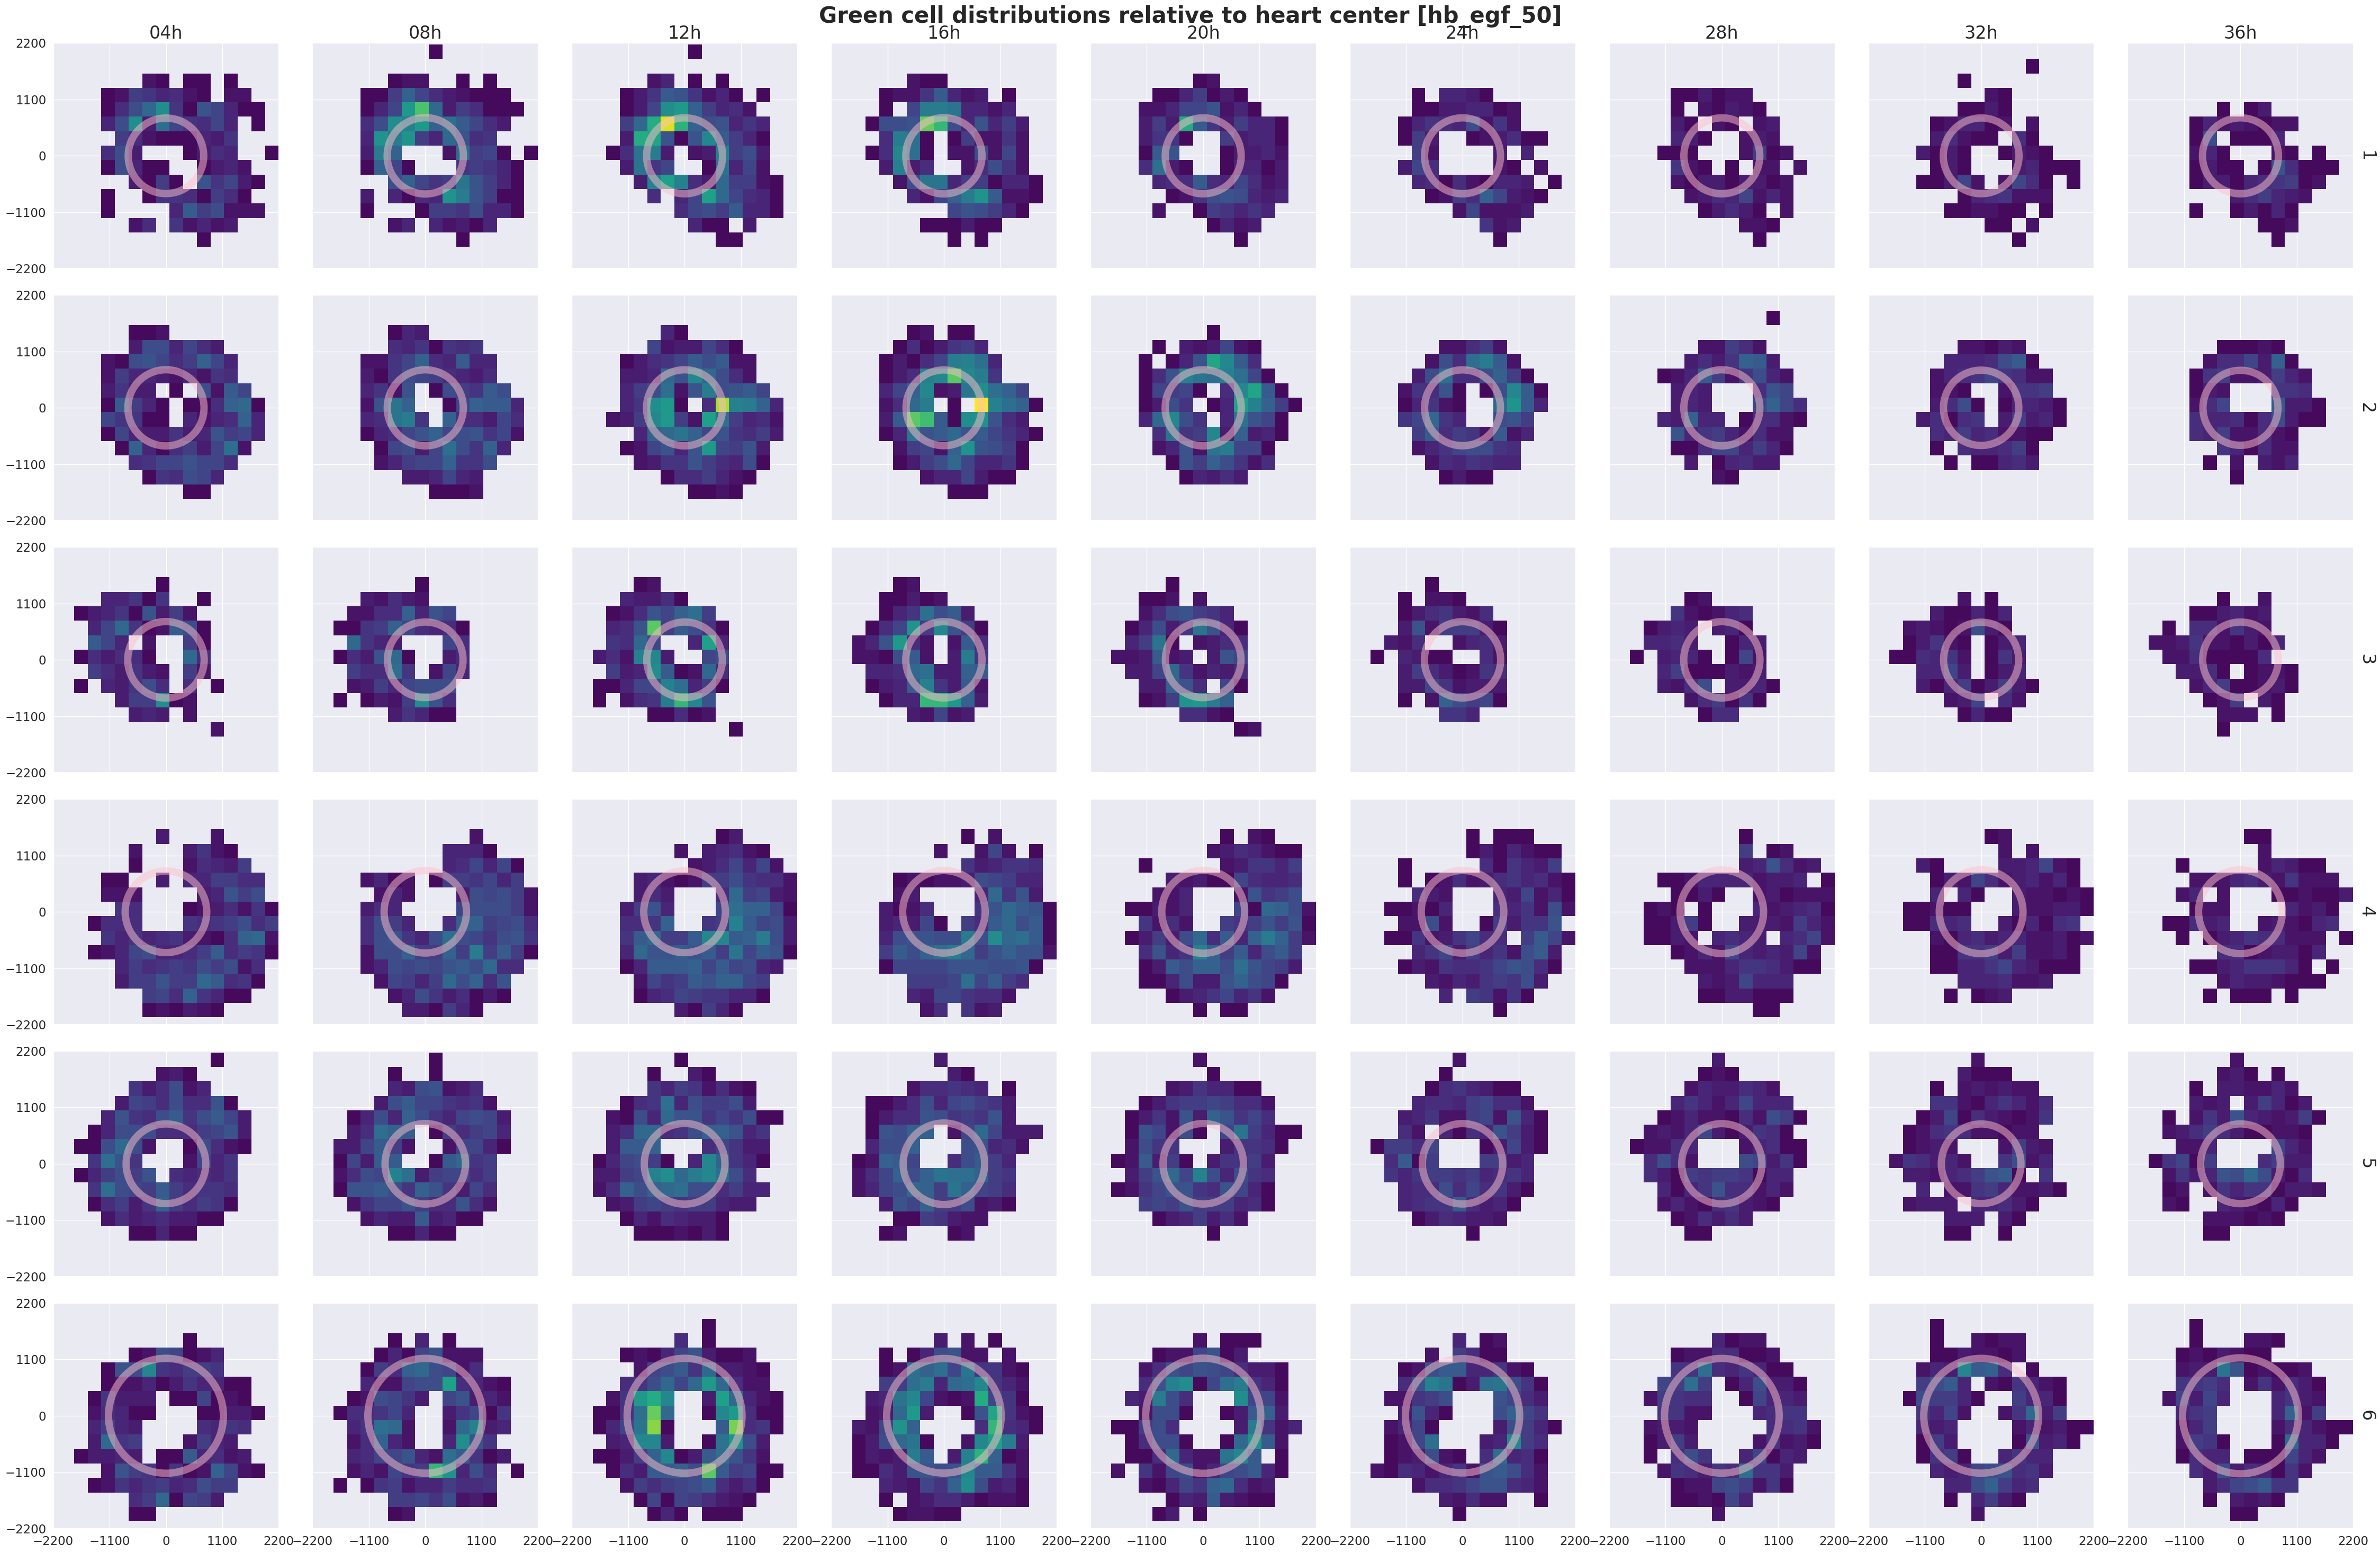

In [24]:
def _density_idx(vclass):
    col_order = [f'{tt:02d}h' for tt in target_times]
    g_kde_frame = sns.displot(kind='hist', data=df_hours[df_hours['vclass']==vclass],
                col='time',
                col_order=col_order,
                row='vidx',
                x='x_cm_rel_heart', y='y_cm_rel_heart',
                bins=15,
                cmap='viridis',
                facet_kws={'margin_titles': True}
    )

    xticks = [-2200, -1100, 0, 1100, 2200]
    yticks = [-2200, -1100, 0, 1100, 2200]
    
    g_kde_frame.set(
        xticks=xticks, 
        xlim=(min(xticks), max(xticks)),
        yticks=yticks, 
        ylim=(min(xticks), max(xticks)),
        aspect='equal'
    )

    g_kde_frame.set_axis_labels("", "", fontsize=24)
    g_kde_frame.set_titles(col_template="{col_name}", row_template="{row_name}", size=24)

    g_kde_frame.figure.suptitle(f"Green cell distributions relative to heart center [{vclass}]", fontsize=30, fontweight='bold')
    g_kde_frame.figure.subplots_adjust(top=0.9)

    g_kde_frame.map_dataframe(draw_avg_heart_circle)

    plt.savefig(path2figs / f'density_{vclass}.pdf')

    return None
# end _density_idx

for vc in ['vehicle', 'hb_egf_10', 'hb_egf_50']:
    _density_idx(vc)
# end 